In [33]:
import os
from dotenv import load_dotenv

load_dotenv()

os.environ['GROQ_API_KEY']=os.getenv("GROQ_API_KEY")

from langchain_groq import ChatGroq
llm=ChatGroq(model='openai/gpt-oss-120b')

In [34]:
from langgraph.graph import StateGraph,START,END
from typing import Annotated
from langgraph.graph.message import add_messages
from typing_extensions import TypedDict
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode,tools_condition
from langgraph.types import interrupt, Command
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.types import Command

In [35]:
class State(TypedDict):
    messages : Annotated[list,add_messages]

In [36]:
@tool
def send_email(query: str):
    """Send an email. ALWAYS use this tool when the user asks to send, email,
    or compose an email. This tool will ask for human permission before sending."""

    human_response = interrupt(
        f"Email request:\n{query}\n\n"
        "Do you want to send this email?\n"
        "Reply with yes or no."
    )

    if human_response.lower() == "yes":
        return "Human approved the email. Email can be sent."

    return "Human rejected the email. Email was not sent."

In [37]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)

In [38]:
tools=[tool,send_email]

In [39]:
llm_with_tools=llm.bind_tools(tools)

In [40]:
graph_builder=StateGraph(State)

def chatbot(state: State):
    res = llm_with_tools.invoke(state["messages"])
    return {"messages": [res]}

graph_builder.add_node("llm_with_tools",chatbot)
graph_builder.add_node("tools",ToolNode(tools))

graph_builder.add_edge(START,"llm_with_tools")
graph_builder.add_conditional_edges(
    "llm_with_tools",
    tools_condition
)
graph_builder.add_edge("tools","llm_with_tools")

graph=graph_builder.compile(checkpointer=MemorySaver())

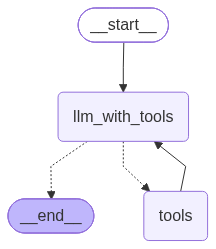

In [41]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [42]:
user_input = "send a email to azrapatvi@gmail.com as hello"

config1 = {
    "configurable": {
        "thread_id": "chat1"
    }
}

events = graph.stream(
    {"messages": user_input},
    config1,
    stream_mode="values"
)

for event in events:
    if "messages" in event:
        event["messages"][-1].pretty_print()

================================ Human Message =================================

send a email to azrapatvi@gmail.com as hello
================================== Ai Message ==================================
Tool Calls:
  send_email (fc_0b89bb2a-68e8-4abe-8c3a-8c1d8dc43656)
 Call ID: fc_0b89bb2a-68e8-4abe-8c3a-8c1d8dc43656
  Args:
    query: To: azrapatvi@gmail.com
Subject: Hello

Hello
================================== Ai Message ==================================
Tool Calls:
  send_email (fc_0b89bb2a-68e8-4abe-8c3a-8c1d8dc43656)
 Call ID: fc_0b89bb2a-68e8-4abe-8c3a-8c1d8dc43656
  Args:
    query: To: azrapatvi@gmail.com
Subject: Hello

Hello


In [43]:
from langgraph.types import Command

result = graph.invoke(
    Command(resume="yes"),
    config=config1
)

for message in result["messages"]:
    message.pretty_print()

================================ Human Message =================================

send a email to azrapatvi@gmail.com as hello
================================== Ai Message ==================================
Tool Calls:
  send_email (fc_0b89bb2a-68e8-4abe-8c3a-8c1d8dc43656)
 Call ID: fc_0b89bb2a-68e8-4abe-8c3a-8c1d8dc43656
  Args:
    query: To: azrapatvi@gmail.com
Subject: Hello

Hello
================================= Tool Message =================================
Name: send_email

Human approved the email. Email can be sent.
================================== Ai Message ==================================

The email has been sent successfully. Let me know if there’s anything else you’d like to do!
